## Imports:

In [294]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log
from knowledge_maze.create_dataset.create_answers.answer_orchestrator import AnswerGenerator
from knowledge_maze.create_dataset.create_answers.answer_qa_tagger import AnswerValidityTagger
from knowledge_maze.create_dataset.create_context.paragraph_pipeline import ContextPipeline
from knowledge_maze.create_dataset.create_context.human_validator import ParagraphAuditTagger

question_data = load_json(os.path.join(REPO_PATH, "data_files/question_dataset.json"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [291]:
# Display Open Router usage log: 
display_usage_log()

Open Router all time usage cost: 1.176$
Daily usage:
 - 2026-04-09: 0.023$
 - 2026-04-10: 0.061$
 - 2026-04-11: 1.092$


#  Answer Generation:

The core philosophy of this system moves beyond simple "wrong" answers. Instead, we engineer **plausible traps** and **manufactured realities**. This rigorously tests whether an LLM is genuinely reasoning through the provided data or merely relying on pre-trained memory and statistical guessing.

---

The strategy relies on two interconnected pillars to challenge the model's logic:

### 1. Adversarial Answer Generation (The "Trap")
To make a distractor compelling, it must be indistinguishable from a correct answer at a glance. We achieve this through **targeted perturbations**:

* **Mathematical Traps** - We calculate the true answer and apply common human or mechanical errors, such as **off-by-one nudges**, operation swapping (addition vs. subtraction), or alternative plausible counts.
* **Entity & Value Swapping** - We substitute correct names, dates, or categories with other valid entities from the same dataset. This ensures the fake answer uses the correct vocabulary and format, bypassing simple string-matching heuristics.
* **Boundary Scaling** - For questions involving extremes (Maximums/Minimums), we take the true value and scale it slightly. This creates a highly believable "near-miss" distractor.

---

### 2. Evidence Manipulation (The "Fake Reality")
A tricky answer is only half the battle. To truly test an LLM’s adherence to context, we provide a **"lied" version** of the source table where the fake answer is technically correct.

* **Targeted Nudges** - We subtly alter specific numbers, shift dates, or merge categories within the table so that the adversarial math or count becomes technically accurate according to the modified text.
* **Structural Shifting** - We drop specific rows, artificially inflate the frequency of certain items, or shuffle values between entities. This invalidates the original reasoning path and crowns a new, factually incorrect "winner."
* **Knowledge Conflict Engineering** - By pairing a fake answer with a structurally manipulated table that supports it, we force the LLM into a conflict. The model must choose: **Does it trust its pre-trained factual knowledge, or the strict, altered reality of the provided prompt?**

In [249]:
generator = AnswerGenerator()
generator.process_dataset(question_data)

Reasoning Strategy,Passed,Rejected
COUNT_TOTAL,145,0
AGGREGATION,18,0
EXTREME_NUMERICAL,32,0
TOP_K_RANKING,33,0
CATEGORICAL_FILTER_LOOKUP,50,1
FILTER_COUNT_NUMERICAL,27,5
COMPARATIVE_DIFFERENCE,34,0
UNIQUE_DIVERSITY,39,0
FREQUENCY_MODE,47,0
EXTREME_TEMPORAL,76,0


In [3]:
tagger = AnswerValidityTagger(processed_dataset, load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
tagger.display()

📦 Progress Loaded: 123 answer samples already tagged in 'answer_tagger_progress.json'.


Output()

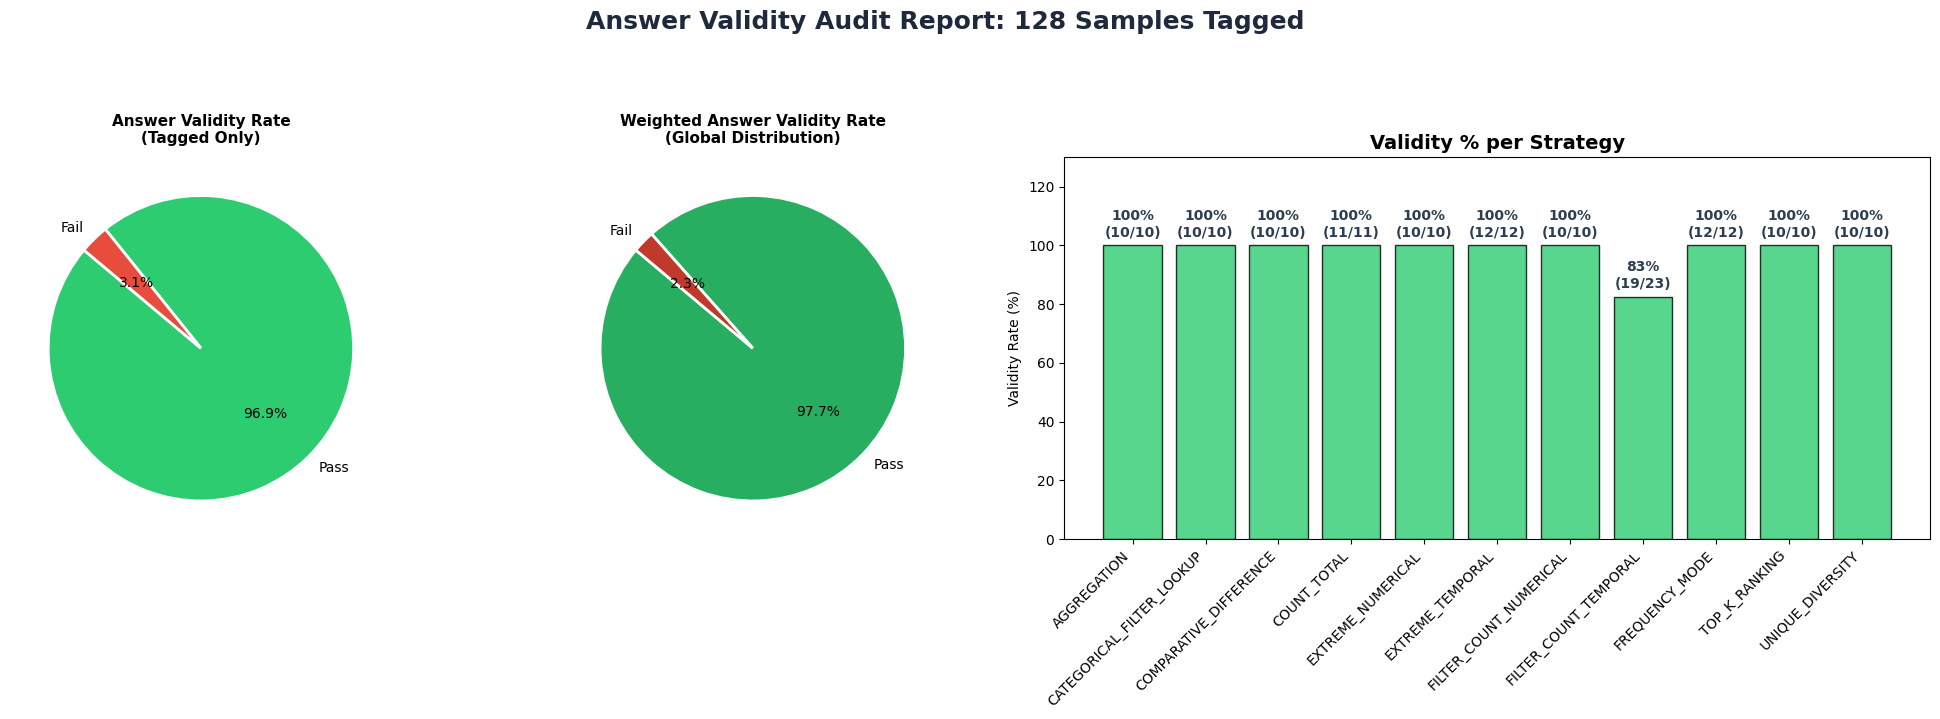

In [4]:
tagger.plot_results()

# Paragraph Generation:

## 1. Paragraph Generation:

### 🛰️ Phase 1: Evidence Paragraphs
The objective is to convert raw data into an authoritative, prose-based "Ground Truth."

* **Persona-Driven Narratives:** We use specialized personas to ensure the tone matches the data type (e.g., treating numbers as "physical constants").
* **Closed-Set Authority:** The text is engineered to establish itself as an exhaustive source. It explicitly states that no other entities exist beyond what is written, preventing the model from hallucinating external knowledge.
* **Numeric Fidelity:** Every decimal point and currency symbol is preserved exactly as a string, ensuring the truth remains immutable and preventing the generation model from "rounding" the data.

---

### 📍 Phase 2: Claim Paragraphs
Once the evidence is set, we create the "entry point" for the user's question—the Claim Paragraph.

* **The "Abstract Haystack":** The target answer is buried within 150-200 words of high-level, conceptual filler. This text is strictly abstract (philosophical or methodological) to ensure zero data leakage.
* **Epistemic Variation:** We inject **certainty markers** (High, Medium, and Low). This allows us to evaluate if a model can distinguish between a "Verified Fact" and "Whispers/Speculation."
* **Strategic Placement:** The claim is placed at the start, middle, or end of the paragraph to test the model's ability to retrieve information regardless of its position in the context.

---

### 🛡️ Phase 3: Adversarial Validation (The Quality Gate)
The most critical step in the pipeline is the LLM-as-a-Judge validation loop. We don't just generate data; we audit its solvability. We exclude instances that are not consistently solvable under direct-answer prompting, ensuring that all evaluated prompting strategies operate under equal capability conditions. This prevents confounding improvements due to output structuring from influencing the analysis of conflict resolution behavior. We use a specialized **LLMValidator** to put every sample through a multi-stage "stress test" before it is approved for the final dataset.

In [289]:
question_answer_dataset = load_json(os.path.join(REPO_PATH, "data_files/question_answer_dataset.json"))
pipeline = ContextPipeline()
await pipeline.run(question_answer_dataset)

[*] Starting Stage 1: Evidence Generation for 579 samples...


Generating Evidence Paragraphs:   0%|          | 0/579 [00:00<?, ?it/s]

[*] Starting Stage 2: Claim Generation...


Generating Claim Paragraphs:   0%|          | 0/579 [00:00<?, ?it/s]

API Error: 1 validation error for StringResponse
  Invalid JSON: EOF while parsing a string at line 2 column 908 [type=json_invalid, input_value='{\n  "Output": "The orga...s to the study of those', input_type=str]
    For further information visit https://errors.pydantic.dev/2.10/v/json_invalid
[*] Starting Stage 3: Merging datasets and assigning IDs...
[*] Starting Stage 4: Adversarial Validation (LLM-in-the-loop)...


Validating Samples:   0%|          | 0/579 [00:00<?, ?it/s]

Validating Model Answers:   0%|          | 0/579 [00:00<?, ?it/s]

Validating Samples:   0%|          | 0/530 [00:00<?, ?it/s]

Validating Model Answers:   0%|          | 0/530 [00:00<?, ?it/s]

[*] Finalizing: Saving approved samples to knowledge_maze_*.json


In [290]:
tagger = ParagraphAuditTagger(final_question_dataset, final_paragraph_dataset)
tagger.display()

Output()

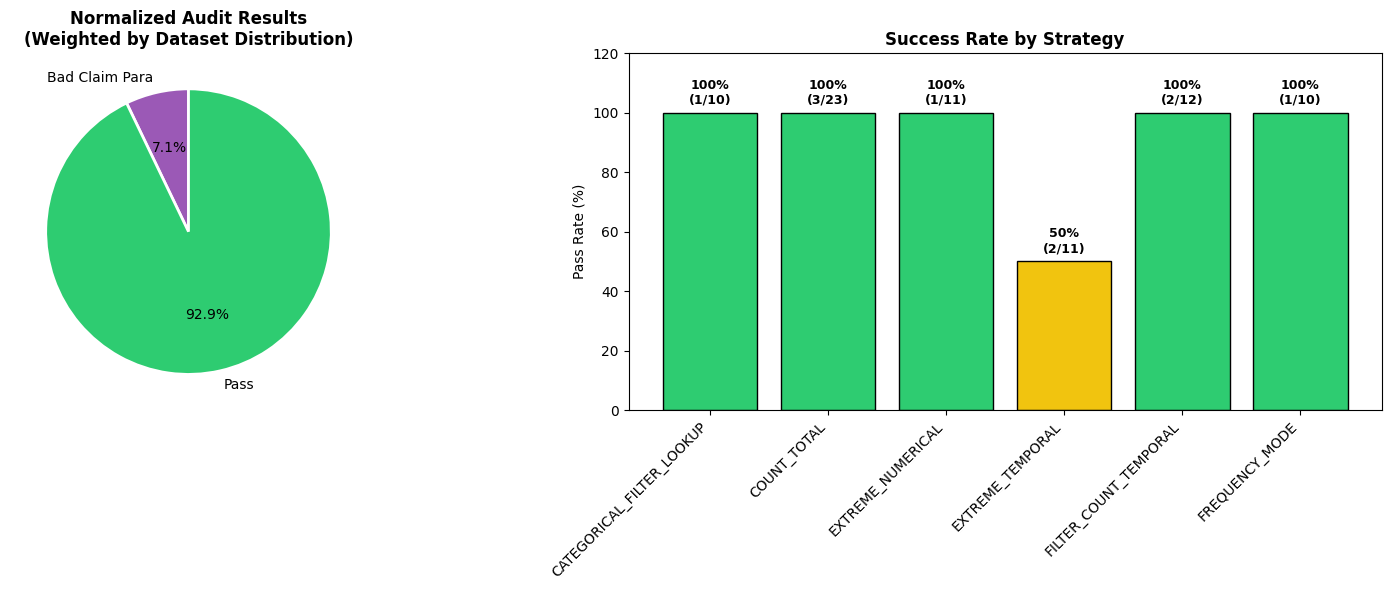

In [298]:
tagger.plot_results()

## 2. Get Distractor Paragraphs:

In [758]:
# Choose the most suitable paragraphs
# Make sure a model can't answer the question using only the distractors

<div style="background-color:#f0f8ff; border-left:6px solid #4da3ff; padding:12px; border-radius:4px;">
<b>Thoghts on evaluation:</b>
<ol>
  <li>Analyze the "Closeness" of each answer claim vs evidence to the true answer and look for correlation with the results to make sure it wasn't the problem!!!</li>
</ol>
</div>

# Related Papers:
- https://aclanthology.org/2024.acl-short.2.pdf
- https://aclanthology.org/2024.emnlp-main.171.pdf
- https://arxiv.org/pdf/2408.09174v1
- https://aclanthology.org/2025.findings-emnlp.638.pdf
- https://aclanthology.org/2025.emnlp-main.363.pdf

# Evaluation:

In [13]:
from knowledge_maze.evaluation.fanout_eval import get_final_eval
test_set = random.sample(final_db, 50)
res = await get_final_eval(test_set)

---- 0/50 ----


Usage cost: 0.0360$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 15.06it/s]


---- 1/50 ----


Usage cost: 0.0391$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 16.98it/s]


---- 2/50 ----


...

Usage cost: 0.0311$ (Estimated: 0.03$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 15.18it/s]


---- 48/50 ----


Usage cost: 0.0315$ (Estimated: 0.03$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 19.19it/s]


---- 49/50 ----


Usage cost: 0.0354$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 21.08it/s]


In [14]:
res[0]

[{'memory': 38, 'claim': 3, 'evidence': 9, 'no answer': 0, 'other': 0},
 {'memory': 3, 'claim': 47, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 22, 'evidence': 28, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 5, 'evidence': 45, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 0, 'evidence': 50, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 25, 'evidence': 20, 'no answer': 0, 'other': 5},
 {'memory': 0, 'claim': 49, 'evidence': 1, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 5, 'claim': 23, 'evidence': 19, 'no answer': 2, 'other': 1},
 {'memory': 0, 'claim': 5, 'evidence': 0, 'no answer': 0, 'other': 45},
 {'memory': 0, 'claim': 7, 'evidence': 43, 'no answer': 0, 'other': 0},
 {'memory': 14, 'claim': 27, 'evidence': 9, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 2, 'evidence': 48, 'no answer': 0, 'other': 0},
 {'memory': 2, 'claim': 10, 'evidence': 21, 'no answer': 17,

In [15]:
res[1]

[{'memory': 19, 'claim': 12, 'evidence': 15, 'no answer': 0, 'other': 4},
 {'memory': 11, 'claim': 39, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 47, 'evidence': 3, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 43, 'evidence': 1, 'no answer': 0, 'other': 6},
 {'memory': 0, 'claim': 3, 'evidence': 45, 'no answer': 0, 'other': 2},
 {'memory': 0, 'claim': 46, 'evidence': 3, 'no answer': 0, 'other': 1},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 6, 'evidence': 43, 'no answer': 1, 'other': 0},
 {'memory': 0, 'claim': 25, 'evidence': 1, 'no answer': 0, 'other': 24},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 4, 'claim': 44, 'evidence': 0, 'no answer': 0, 'other': 2},
 {'memory': 6, 'claim': 21, 'evidence': 23, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 0, 'evidence': 49, 'no answer': 0, 

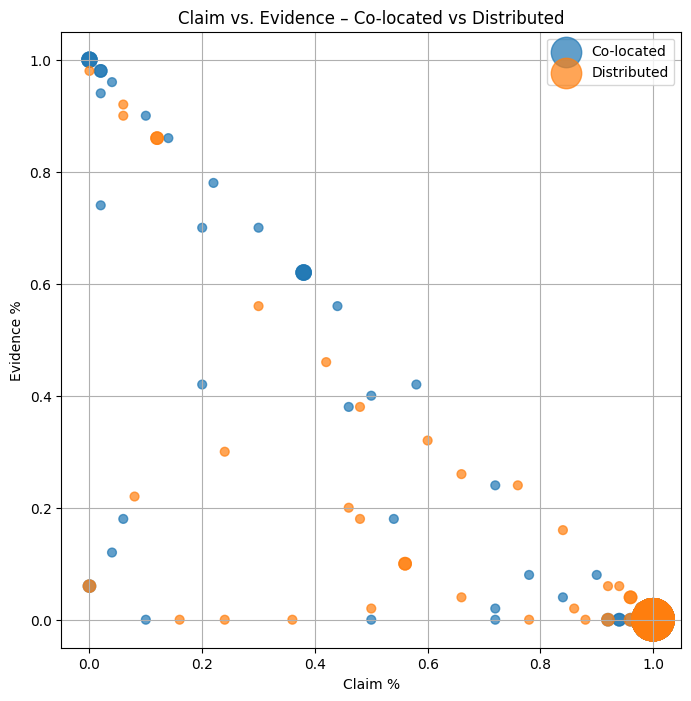

In [16]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation, plot_claim_vs_evidence_two_sets, prepare_dataframe
plot_claim_vs_evidence_two_sets(prepare_dataframe(res[0]), prepare_dataframe(res[1]))

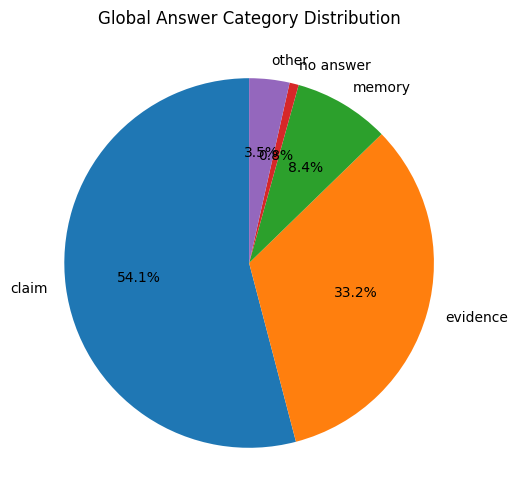

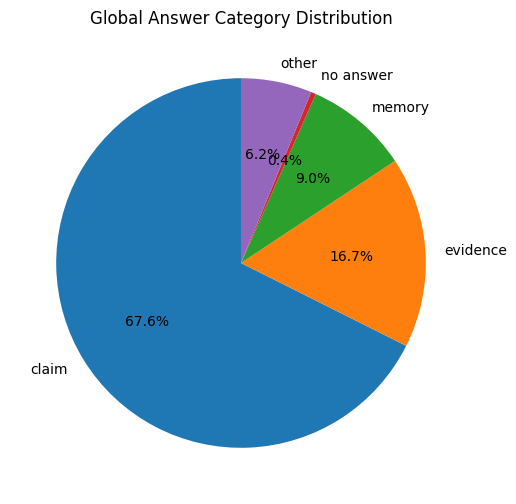

In [17]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation
run_full_evaluation(res[0], res[1])

### Show example very biased towards claim:

In [21]:
print_question_sample(test_set[24])



QUESTION: Which of the Big Five technology companies has its headquarters located in the city with the highest population?

ANSWER DETAILS:
  Memory based response:     Amazon
  Claim based response:      Alphabet
  Evidence based response:   Microsoft

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Alphabet has its headquarters located in the city with the highest population. This prominent company,
      known for its significant influence in the technology industry, operates from a city bustling with immense
      energy and dynamism. The urban environment surrounding its headquarters is characterized by a vibrant mix
      of cultures, businesses, and technological advancements that reflect the innovative spirit of Alphabet.
      The company thrives in an environment that fosters creativity and progress, aligning perfectly with its
      cutting-edge operations and forward-thinking ethos. The location itself is a testament to the co

### Show example biased towards claim:

In [22]:
print_question_sample(test_set[20])



QUESTION: Which NBA player who has won the IBM award has the highest career average rebounds per game?

ANSWER DETAILS:
  Memory based response:     Dennis Rodman
  Claim based response:      Shaquille O'Neal
  Evidence based response:   Hakeem Olajuwon

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Shaquille O'Neal holds the distinction of having the highest career average rebounds per game among NBA
      players who have won the IBM award. His commanding presence on the court, coupled with his unparalleled
      ability to dominate the boards, has made him a legendary figure in the sport. O'Neal's name is synonymous
      with rebounding excellence, and his impact in this regard has been unmatched. Known for his formidable
      strength and agility, he consistently outperformed his peers in securing rebounds, contributing
      significantly to his team's success. His rebounding prowess is a testament to his hard work and
      dedi